# Laboratorio 5. Agentes en el Arcade Learning Environment (ALE): Space Invaders

Fernando Rueda - 23748

CC3092 Deep Learning y Sistemas Inteligentes

En este notebook investigo el Arcade Learning Environment y los espacios de observación y acción de los entornos de Atari, y luego construyo un módulo reutilizable para crear entornos, ejecutar agentes y grabar video de las partidas. No entreno un agente inteligente, el objetivo es dejar funcionando la infraestructura para que un agente simple, aleatorio o de regla fija, interactúe con ALE/SpaceInvaders-v5 y genere un video del juego. Este mismo código será la base para entrenar agentes en el proyecto futuro.

## 1. El Arcade Learning Environment (ALE)

### Qué es ALE y qué problema resuelve

El Arcade Learning Environment es una plataforma que expone los juegos de la consola Atari 2600 como entornos de aprendizaje por refuerzo, con una interfaz común para que un agente reciba observaciones, ejecute acciones y obtenga recompensas. El problema que resuelve es la falta de un banco de pruebas estandarizado y variado para evaluar agentes de propósito general, ALE ofrece decenas de juegos distintos bajo la misma API, de modo que un mismo algoritmo puede medirse en muchas tareas sin cambiar el código. Internamente ALE no reimplementa los juegos, sino que corre las ROM originales de Atari 2600 sobre el emulador Stella, y se limita a leer la pantalla y la memoria del emulador, inyectar las acciones del joystick y traducir el marcador del juego a una señal de recompensa. Así, los juegos con los que interactúa el agente son exactamente los cartuchos originales, y Stella es el motor de emulación que los hace correr.

Fuente: Bellemare, M. et al. (2013). The Arcade Learning Environment: An Evaluation Platform for General Agents, JAIR, y documentación de ale-py, Farama Foundation.

### Variantes de un mismo juego en ALE

Un mismo juego se expone en varias variantes que cambian qué observa el agente y cómo se comporta el entorno. ALE/SpaceInvaders-v5 entrega como observación la imagen RGB de la pantalla, mientras que la variante con sufijo -ram (ALE/SpaceInvaders-ram-v5) entrega los 128 bytes de la memoria de la consola en vez de la imagen. Más allá del tipo de observación, las variantes se ajustan con parámetros. frameskip fija cuántos fotogramas del emulador avanza cada acción, en la familia -v5 el valor por defecto es 4, es decir el agente decide una vez y esa acción se repite cuatro fotogramas. repeat_action_probability es la probabilidad de acciones pegajosas (sticky actions), con la que el entorno repite la acción anterior en lugar de la nueva, en -v5 vale 0.25 e introduce estocasticidad para evitar que el agente memorice una secuencia fija de movimientos. full_action_space decide si el espacio de acción es el conjunto completo de 18 acciones del joystick de Atari o solo el subconjunto mínimo con sentido para ese juego, que en Space Invaders son 6. La versión -v5 es la recomendada por ALE porque estandariza estos valores.

Fuente: Machado, M. et al. (2018). Revisiting the Arcade Learning Environment, JAIR, y documentación de entornos Atari de Gymnasium.

### Frame skipping

El frame skipping consiste en que el agente elige una acción cada k fotogramas y esa misma acción se aplica en los fotogramas intermedios, en vez de decidir en cada uno. Es importante por dos razones. Primero por velocidad, decidir una vez cada cuatro fotogramas reduce a la cuarta parte el número de inferencias del agente y de pasos que hay que procesar, lo que acelera muchísimo la simulación y el entrenamiento sin perder casi información, porque entre fotogramas consecutivos de un juego de Atari el cambio es mínimo. Segundo por la dinámica del aprendizaje, con salto de fotogramas cada acción tiene un efecto más visible sobre el estado siguiente, lo que hace la recompensa menos dispersa y la asignación de crédito temporal más fácil. El costo es de resolución temporal, un salto muy grande puede hacer que el agente pierda eventos rápidos, por eso cuatro es el valor habitual, un compromiso entre velocidad y control fino. Como el salto suele combinarse con tomar el máximo de los dos últimos fotogramas, también corrige el parpadeo de sprites propio del hardware del Atari 2600.

Fuente: Mnih, V. et al. (2015). Human-level control through deep reinforcement learning, Nature, y Machado et al. (2018).

### El juego Space Invaders

En Space Invaders el jugador controla un cañón que se mueve horizontalmente en la parte baja de la pantalla y dispara hacia arriba contra una formación de alienígenas que descienden y disparan de vuelta. El objetivo es destruir a todos los invasores antes de que lleguen abajo, esquivando sus disparos y protegiéndose tras unos búnkeres que se van destruyendo. Se dispone de varias vidas y el episodio termina cuando se pierden todas o los invasores alcanzan al jugador. La puntuación del juego original sube al destruir invasores, valen más los de las filas superiores, y una nave nodriza ocasional da un bono grande. En el entorno de ALE esa puntuación es justamente la señal de recompensa, la recompensa de cada paso es el incremento del marcador del juego en ese paso, de modo que maximizar la recompensa acumulada equivale a maximizar el puntaje. Por eso un agente aleatorio suele obtener una recompensa baja pero no nula, ya que de vez en cuando dispara y acierta a algún invasor por azar.

Fuente: documentación del entorno SpaceInvaders de Gymnasium y ALE.

## 2. Espacios de observación y acción en entornos Atari

### Observación por defecto e imágenes frente a vectores

La observación por defecto de ALE/SpaceInvaders-v5 es un Box de forma 210x160x3 y tipo uint8, es decir la imagen RGB de la pantalla del Atari, con valores de 0 a 255 por canal. Frente a CartPole-v1 del laboratorio anterior, cuya observación es un Box de solo cuatro números reales con el estado físico ya resumido (posición y velocidad del carro, ángulo y velocidad angular del poste), la diferencia es enorme. En CartPole el estado viene dado y de baja dimensión, mientras que en Space Invaders el agente recibe 210x160x3 = 100800 valores crudos de píxeles y debe extraer por sí mismo qué es relevante, dónde está el cañón, dónde los invasores y las balas. Trabajar con imágenes implica una dimensionalidad muchísimo mayor, la necesidad de una red convolucional para procesar la entrada, un preprocesamiento típico para reducir el costo, y que el estado no es del todo Markoviano en un solo fotograma, porque a partir de una imagen fija no se puede saber la velocidad ni la dirección de los objetos, lo que obliga a apilar varios fotogramas.

Fuente: documentación de Gymnasium, espacios y entornos Atari.

### Observación en RAM

La variante con obs_type="ram" entrega como observación los 128 bytes de la memoria de la consola Atari 2600 en vez de la imagen. Es un vector de 128 valores enteros de 0 a 255 que contiene el estado interno del juego, posiciones, contadores, vidas y marcador, tal como el cartucho los guarda. Podría preferirse sobre la imagen cuando se quiere un estado compacto y de baja dimensión que no requiere una red convolucional ni preprocesamiento de píxeles, lo que hace el entrenamiento más liviano y rápido. La contraparte es que esos bytes son crudos y sin documentar, su significado varía por juego y no tienen la estructura espacial que una CNN aprovecha en la imagen, por lo que en la práctica los mejores resultados generales se han obtenido con la observación en imagen.

Fuente: Bellemare et al. (2013) y documentación de ale-py.

### Espacio de acción de Space Invaders

El espacio de acción de Space Invaders es un Discrete de 6, es decir seis acciones discretas que corresponden al joystick mínimo del juego. NOOP no hace nada y deja al cañón quieto. FIRE dispara sin moverse. RIGHT mueve el cañón a la derecha y LEFT a la izquierda. RIGHTFIRE mueve a la derecha y dispara a la vez, y LEFTFIRE mueve a la izquierda y dispara a la vez. Estas seis cubren todo lo que el jugador necesita, moverse en las dos direcciones, disparar, y combinar movimiento con disparo. Con full_action_space se expondrían las 18 acciones del joystick de Atari, pero las 12 restantes no tienen un efecto útil en este juego.

Fuente: get_action_meanings de ALE y documentación de Gymnasium.

### Wrappers AtariPreprocessing y FrameStackObservation

AtariPreprocessing es el wrapper que aplica el preprocesamiento estándar de la literatura de DQN sobre un entorno Atari. Sus transformaciones típicas son convertir la imagen a escala de grises, redimensionarla de 210x160 a 84x84 píxeles, aplicar el salto de fotogramas tomando el máximo de los dos últimos, y opcionalmente recortar la recompensa a su signo (-1, 0, +1) para estabilizar el entrenamiento entre juegos con escalas de puntaje muy distintas. Con esto la observación pasa de una imagen RGB grande a una imagen pequeña en gris, mucho más barata de procesar. FrameStackObservation (o FrameStack) apila las últimas k observaciones, normalmente cuatro, en un solo tensor. Se usa junto con AtariPreprocessing porque, como una sola imagen no revela el movimiento, apilar cuatro fotogramas consecutivos le da al agente información de velocidad y dirección, recuperando la propiedad de Markov que un fotograma aislado no tiene. La combinación habitual es entonces AtariPreprocessing más un apilado de cuatro fotogramas de 84x84, que es la entrada clásica de un agente DQN en Atari.

Fuente: Mnih et al. (2015) y documentación de wrappers de Gymnasium.

## 3. Módulo de desarrollo: funciones para interactuar con ALE

Construyo un módulo de funciones reutilizables para crear entornos, ejecutar agentes y grabar video de las partidas. Las funciones son crear_entorno, agente_aleatorio, agente_regla_simple, ejecutar_episodio y generar_video_agente, y están escritas para funcionar tanto con Space Invaders como con cualquier otro entorno de Gymnasium. Fijo semillas para que los resultados sean reproducibles.

In [1]:
import os
import glob
import gymnasium as gym
import ale_py
import numpy as np
import matplotlib.pyplot as plt
from gymnasium.wrappers import RecordVideo

# En Gymnasium 1.x hay que registrar explícitamente los entornos de ALE.
gym.register_envs(ale_py)

print("gymnasium:", gym.__version__)
print("ale-py:", ale_py.__version__)

gymnasium: 1.3.0
ale-py: 0.12.1


### Inspección de los espacios reales de ALE/SpaceInvaders-v5

Creo el entorno e imprimo sus espacios de observación y acción para confirmar lo investigado, la observación es una imagen RGB de 210x160x3 y la acción es discreta con seis valores. También muestro un fotograma de ejemplo para visualizar cómo se ve la observación.

Espacio de observación: Box(0, 255, (210, 160, 3), uint8)
  tipo: Box | forma: (210, 160, 3) | dtype: uint8
Espacio de acción: Discrete(6)
  acciones: ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']
Forma de la observación inicial: (210, 160, 3)


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


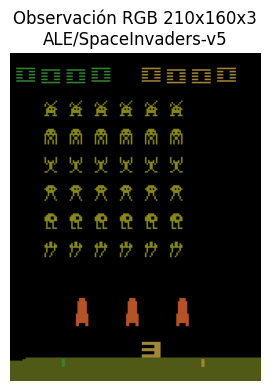

In [2]:
env = gym.make("ALE/SpaceInvaders-v5", render_mode="rgb_array")
print("Espacio de observación:", env.observation_space)
print("  tipo:", type(env.observation_space).__name__,
      "| forma:", env.observation_space.shape,
      "| dtype:", env.observation_space.dtype)
print("Espacio de acción:", env.action_space)
print("  acciones:", env.unwrapped.get_action_meanings())

obs, info = env.reset(seed=0)
print("Forma de la observación inicial:", obs.shape)

plt.figure(figsize=(3, 4))
plt.imshow(obs)
plt.title("Observación RGB 210x160x3\nALE/SpaceInvaders-v5")
plt.axis("off")
plt.tight_layout(); plt.show()
env.close()

### crear_entorno

crear_entorno crea y retorna un entorno de Gymnasium a partir de su nombre. Si se pasa video_folder, envuelve el entorno con RecordVideo para grabar los episodios que indique episode_trigger, por defecto todos. Fuerza render_mode="rgb_array" cuando se va a grabar, que es lo que RecordVideo necesita para capturar los fotogramas. La función es genérica, sirve para Space Invaders o cualquier otro entorno de Gymnasium.

In [3]:
def crear_entorno(nombre_entorno, video_folder=None, name_prefix="video",
                  episode_trigger=None, **kwargs):
    """Crea un entorno de Gymnasium; si video_folder no es None lo envuelve con RecordVideo."""
    if video_folder is not None:
        kwargs.setdefault("render_mode", "rgb_array")   # RecordVideo necesita rgb_array
    env = gym.make(nombre_entorno, **kwargs)
    if video_folder is not None:
        if episode_trigger is None:
            episode_trigger = lambda ep: True           # por defecto graba todos los episodios
        env = RecordVideo(env, video_folder=video_folder,   # RecordVideo crea la carpeta
                          episode_trigger=episode_trigger, name_prefix=name_prefix)
    return env

### agente_aleatorio

agente_aleatorio recibe la observación actual y el entorno, y retorna una acción muestreada al azar del espacio de acción con env.action_space.sample(). No usa la observación, sirve como línea base (baseline) sin ningún entrenamiento.

In [4]:
def agente_aleatorio(observation, env):
    """Baseline: retorna una acción aleatoria del espacio de acción, ignora la observación."""
    return env.action_space.sample()

### ejecutar_episodio

ejecutar_episodio corre un episodio completo con la función de agente indicada, hasta que terminated o truncated sea verdadero o se alcancen max_steps. Retorna el número de pasos ejecutados y la recompensa total (return) acumulada del episodio, siguiendo el patrón estándar de Gymnasium con la tupla de cinco elementos que devuelve step.

In [5]:
def ejecutar_episodio(env, funcion_agente, max_steps=10000, seed=None):
    """Ejecuta un episodio completo y devuelve (pasos, recompensa_total)."""
    obs, info = env.reset(seed=seed)
    recompensa_total = 0.0
    terminado = False
    t = 0
    while not terminado and t < max_steps:
        accion = funcion_agente(obs, env)
        obs, r, terminated, truncated, info = env.step(accion)
        recompensa_total += r
        t += 1
        terminado = terminated or truncated
    return t, recompensa_total

### agente_regla_simple

Además del agente aleatorio implemento un agente de regla simple no aprendida, solo con conocimiento del dominio. La regla es disparar la mayor parte del tiempo y de vez en cuando moverse a un lado disparando, para cubrir más ancho de pantalla. No aprende nada, pero al disparar de forma casi constante acierta a más invasores que el azar puro, y sirve como una segunda referencia por encima del agente aleatorio.

In [6]:
def agente_regla_simple(observation, env):
    """Regla fija sin aprendizaje: dispara casi siempre y a veces se mueve disparando."""
    # 0 NOOP, 1 FIRE, 2 RIGHT, 3 LEFT, 4 RIGHTFIRE, 5 LEFTFIRE
    u = np.random.random()
    if u < 0.8:
        return 1              # FIRE, disparar en el lugar la mayor parte del tiempo
    elif u < 0.9:
        return 4              # RIGHTFIRE, moverse a la derecha disparando
    else:
        return 5              # LEFTFIRE, moverse a la izquierda disparando

# Comprobación rápida sin grabar video, un episodio de cada agente con la misma semilla.
np.random.seed(0)
env_prueba = crear_entorno("ALE/SpaceInvaders-v5")
env_prueba.action_space.seed(0)
pasos_a, ret_a = ejecutar_episodio(env_prueba, agente_aleatorio, seed=0)
pasos_r, ret_r = ejecutar_episodio(env_prueba, agente_regla_simple, seed=0)
env_prueba.close()
print(f"Agente aleatorio:    pasos = {pasos_a:4d} | recompensa total = {ret_a:.0f}")
print(f"Agente regla simple: pasos = {pasos_r:4d} | recompensa total = {ret_r:.0f}")

Agente aleatorio:    pasos =  298 | recompensa total = 35
Agente regla simple: pasos =  585 | recompensa total = 155
